# Hotel Booking Demand Analysis
## 1. Introduction

This project analyzes booking demand and cancellations for city hotels and resort hotels in Portugal using the
**Hotel Booking Demand** dataset: 119,390 bookings with arrival dates from July 2015 to August 2017,
including bookings that were later canceled.

**Data source:** Antonio, N., de Almeida, A., & Nunes, L. (2019). *Hotel booking demand datasets.*
Data in Brief, 22, 41–49. Available on Kaggle as `hotel_bookings.csv`.
### Key Questions

**Demand**
1. How does booking demand vary across months and years, and is there clear seasonality?
2. How many bookings actually turn into stays, and how does that change the picture of demand?
3. Do the City Hotel and the Resort Hotel follow different seasonal patterns?

**Cancellations**

4. Which booking characteristics are associated with higher cancellation rates?
5. Which factors still predict cancellation when considered together, and how well can a simple model predict it?

### Notebook Structure
1. Introduction
2. Data Overview
3. Data Cleaning
4. Demand Analysis
5. Cancellation Analysis
6. Predicting Cancellation (Logistic Regression)
7. Key Findings and Recommendations

### Setup
All libraries are imported here so the notebook can be run from top to bottom.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch            # custom legend entries (Section 4.4)
from matplotlib.ticker import PercentFormatter  # percentage axis labels (Section 4.5)
hotel_data = pd.read_csv('hotel_bookings.csv')
hotel_data.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Data Overview

Before cleaning, check the size of the data, column types, value ranges, and missing values.

In [2]:
hotel_data.info()
hotel_data.describe() # 32 columns, 119390 entries


<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [3]:
missing = hotel_data.isna().sum()
missing[missing > 0]

children         4
country        488
agent        16340
company     112593
dtype: int64

In [4]:
hotel_data['arrival_date_year'].value_counts()
hotel_data['is_canceled'].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [5]:
hotel_data['arrival_date_month'].value_counts()
hotel_data[hotel_data['arrival_date_year']==2016]['arrival_date_month'].value_counts()
hotel_data['is_canceled'].value_counts(normalize=True)

is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

**Overview notes**
- 119,390 bookings and 32 columns; 37% of bookings were canceled.
- Arrivals run from July 2015 to August 2017, so **2015 and 2017 are partial years** and only 2016 covers all 12 months.
- Missing values appear in `children` (4), `country` (488), `agent` (16,340), and `company` (112,593).
- A few values are impossible (negative or extreme prices, bookings with no guests) and are handled in Section 3.

## 3. Data Cleaning

Worked on a copy (`df`) so the raw data stays available for comparison, and record the starting
row count so it can report exactly how much data the cleaning removes.

In [6]:
df = hotel_data.copy()
n_start = len(df)

In [7]:
df.duplicated().sum()

np.int64(31994)

### 3.1 Missing Values & Impossible Rows

In [8]:
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0)      # 0 = no agent
df['company'] = df['company'].fillna(0)  # 0 = no company
no_guests = (df['adults'] + df['children'] + df['babies']) == 0
bad_adr = (df['adr'] < 0) | (df['adr'] > 1000)
df = df[~no_guests & ~bad_adr]

### 3.2 New Column for Analysis

In [9]:
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d'
)
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['realized'] = df['is_canceled'] == 0

In [10]:
print(f"Rows: {n_start} → {len(df)} ({n_start - len(df)} removed)")
dups = hotel_data[hotel_data.duplicated()]
print("Duplicate rows:", len(dups))
print("Share canceled:", round(dups['is_canceled'].mean() * 100, 1), "%")
print("Share City Hotel:", round((dups['hotel'] == 'City Hotel').mean() * 100, 1), "%")

Rows: 119390 → 119208 (182 removed)
Duplicate rows: 31994
Share canceled: 63.1 %
Share City Hotel: 81.0 %


In [11]:
print("No-guest bookings:", no_guests.sum())
print("Bad ADR rows:", bad_adr.sum())
print(f"Rows: {n_start} → {len(df)} ({n_start - len(df)} removed)")

No-guest bookings: 180
Bad ADR rows: 2
Rows: 119390 → 119208 (182 removed)


**Cleaning summary**
- Filled missing values: `children` (4) with 0; `country` (488) with "Unknown"; `agent` and `company` with 0, since a missing value means the booking was not made through an agent or company.
- Removed 180 bookings with no guests and 2 with invalid prices (one negative ADR, one ADR of 5,400), 182 rows in total (0.15% of the data).
- Kept 31,994 identical rows. The dataset has no booking ID, and 81% of these rows are City Hotel bookings and 63% are canceled, which is consistent with group bookings recorded as one row per room rather than data errors.
- Added `arrival_date`, `total_nights`, and `realized` (not canceled) columns for later analysis.
- Final dataset: 119,208 bookings.

## 4. Demand Analysis

Two measures of demand are used throughout this section:
- **Bookings:** every reservation, including ones later canceled (booking requests).
- **Realized stays:** bookings that were not canceled (guests who actually arrived).

The gap between them matters: 37% of bookings are canceled, so counting bookings alone overstates demand.

### 4.1 Bookings vs. Realized Stays

In [12]:
monthly = df.groupby(df['arrival_date'].dt.to_period('M')).agg(
    bookings=('realized', 'size'),   # all bookings, including canceled
    stays=('realized', 'sum')        # only bookings that turned into stays
)
monthly['cancel_rate'] = 1 - monthly['stays'] / monthly['bookings']
monthly

,bookings,stays,cancel_rate
arrival_date,,,
2015-07,2774,1515,0.453857
2015-08,3883,2285,0.411537
2015-09,5109,3016,0.409669
2015-10,4951,3219,0.349828
2015-11,2337,1851,0.207959
2015-12,2913,1940,0.334020
2016-01,2248,1691,0.247776
2016-02,3884,2549,0.343718
2016-03,4818,3342,0.306351


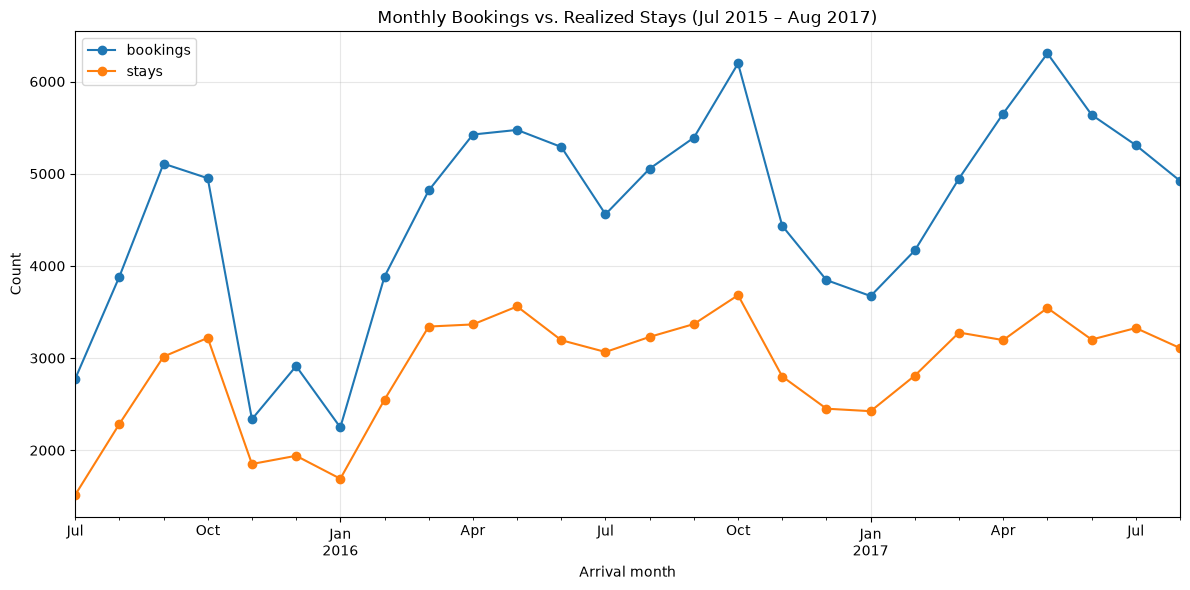

In [13]:
ax = monthly[['bookings', 'stays']].plot(figsize=(12, 6), marker='o')
ax.set_title('Monthly Bookings vs. Realized Stays (Jul 2015 – Aug 2017)')
ax.set_xlabel('Arrival month')
ax.set_ylabel('Count')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.2 Did Growth in Bookings Turn Into Growth in Stays?

In [14]:
months = range(1, 9)  # January to August

def jan_aug(year, col):
    return monthly.loc[[pd.Period(f'{year}-{m:02d}', 'M') for m in months], col].sum()

for col in ['bookings', 'stays']:
    a, b = jan_aug(2016, col), jan_aug(2017, col)
    print(f"{col}: {a} → {b} ({(b - a) / a * 100:+.1f}%)")

bookings: 36755 → 40619 (+10.5%)
stays: 23997 → 24885 (+3.7%)


**Finding:** from January–August 2016 to January–August 2017, bookings grew about **10.5%**, but
realized stays grew only about **3.7%**. Most of the booking growth was absorbed by cancellations,
which rose to about 43% in April–June 2017. Counting all bookings as demand would overstate growth.

### 4.3 Monthly Bookings by Year

In [15]:
#Booking Demand Analysis
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
               'August', 'September', 'October', 'November', 'December']

In [16]:
monthly_data = df.groupby([
    'arrival_date_year','arrival_date_month'
]).size()
monthly_data = monthly_data.unstack()
monthly_data = monthly_data[month_order]
monthly_data

arrival_date_month,January,February,March,April,May,June,July,August,September,October,November,December
arrival_date_year,,,,,,,,,,,,
2015,NaN,NaN,NaN,NaN,NaN,NaN,2774.0,3883.0,5109.0,4951.0,2337.0,2913.0
2016,2248.0,3884.0,4818.0,5425.0,5475.0,5290.0,4560.0,5055.0,5391.0,6196.0,4434.0,3846.0
2017,3673.0,4168.0,4948.0,5653.0,6305.0,5639.0,5310.0,4923.0,NaN,NaN,NaN,NaN


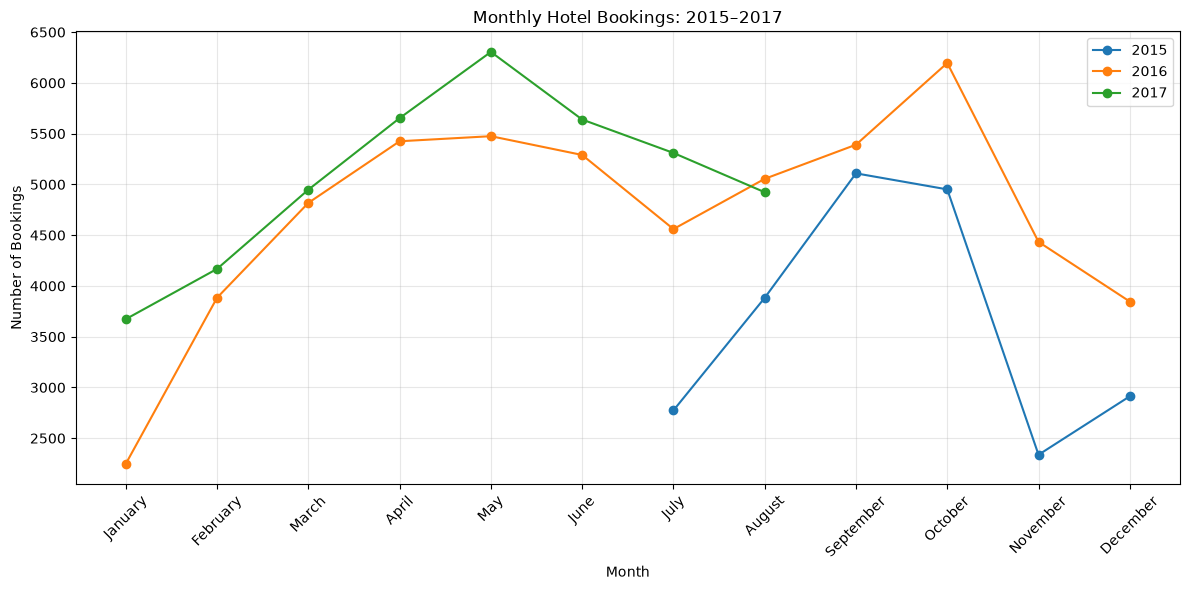

In [17]:
plt.figure(figsize=(12, 6))
for year in [2015, 2016, 2017]:
    plt.plot(monthly_data.columns, monthly_data.loc[year].values, marker='o', label=str(year))

plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.title('Monthly Hotel Bookings: 2015–2017')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Finding:** bookings follow a clear seasonal pattern: lowest in January, rising through spring,
and peaking in spring and again in September–October. 2017 sits above 2016 in most months.

### 4.4 Year-over-Year Booking Growth
Each month is compared with the same month one year earlier, using only months present in both years.

In [18]:
months_jan_aug = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August'
]
jan_aug_data_2016 = monthly_data.loc[2016, months_jan_aug]
jan_aug_data_2017 = monthly_data.loc[2017, months_jan_aug]
percent_change_2016_2017 = (
    ( jan_aug_data_2017- jan_aug_data_2016 )
    / jan_aug_data_2016
    * 100
)
percent_change_2016_2017.round(2)

arrival_date_month
January     63.39
February     7.31
March        2.70
April        4.20
May         15.16
June         6.60
July        16.45
August      -2.61
dtype: float64

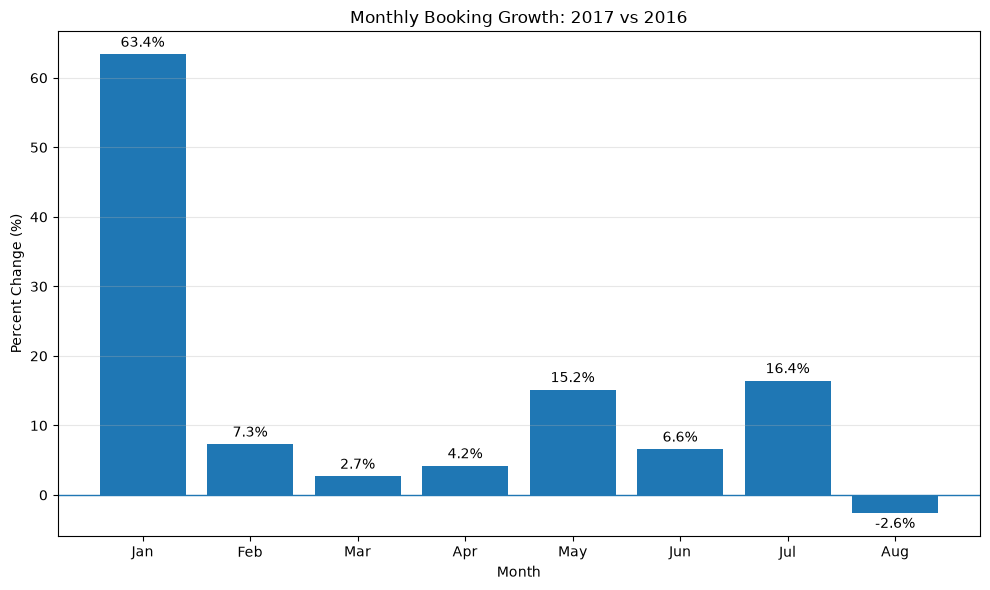

In [19]:
months_short = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug']
plt.figure(figsize=(10, 6))
growth_change_2016_2017 = plt.bar(
    months_short,
    percent_change_2016_2017.values
)
plt.axhline(0, linewidth=1)
plt.title('Monthly Booking Growth: 2017 vs 2016')
plt.xlabel('Month')
plt.ylabel('Percent Change (%)')

plt.grid(axis='y', alpha=0.3)

plt.bar_label(
    growth_change_2016_2017,
    fmt='%.1f%%',
    padding=3
)

plt.tight_layout()
plt.show()

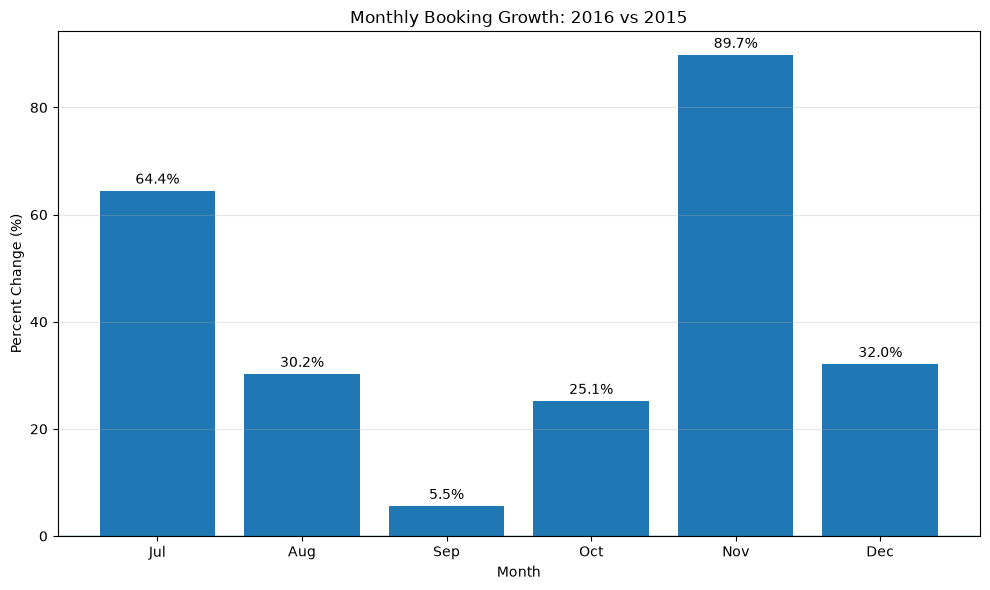

In [20]:
months_july_dec = ['July', 'August', 'September', 'October', 'November', 'December']
jul_dec_data_2015 = monthly_data.loc[2015, months_july_dec]
jul_dec_data_2016 = monthly_data.loc[2016, months_july_dec]
percent_change_2015_2016 = (
    ( jul_dec_data_2016- jul_dec_data_2015 )
    / jul_dec_data_2015
    * 100
)
percent_change_2015_2016.round(2)
months_short_2 = ['Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.figure(figsize=(10, 6))
growth_change_2015_2016= plt.bar(
    months_short_2,
    percent_change_2015_2016.values
)
plt.axhline(0, linewidth=1)
plt.title('Monthly Booking Growth: 2016 vs 2015')
plt.xlabel('Month')
plt.ylabel('Percent Change (%)')

plt.grid(axis='y', alpha=0.3)

plt.bar_label(
    growth_change_2015_2016,
    fmt='%.1f%%',
    padding=3
)

plt.tight_layout()
plt.show()

In [21]:
growth_table_2015_vs_2016= pd.DataFrame({
    "Months": percent_change_2015_2016.index,
    "YoY Growth (%)": percent_change_2015_2016.values
})
growth_table_2015_vs_2016['Comparison'] = '2016 vs 2015'
growth_table_2015_vs_2016

,Months,YoY Growth (%),Comparison
0,July,64.383562,2016 vs 2015
1,August,30.182848,2016 vs 2015
2,September,5.519671,2016 vs 2015
3,October,25.146435,2016 vs 2015
4,November,89.730424,2016 vs 2015
5,December,32.028836,2016 vs 2015


In [22]:
growth_table_2016_vs_2017= pd.DataFrame({
    "Months": percent_change_2016_2017.index,
    "YoY Growth (%)": percent_change_2016_2017.values
})
growth_table_2016_vs_2017['Comparison'] = '2017 vs 2016'
growth_table_2016_vs_2017

,Months,YoY Growth (%),Comparison
0,January,63.389680,2017 vs 2016
1,February,7.312049,2017 vs 2016
2,March,2.698215,2017 vs 2016
3,April,4.202765,2017 vs 2016
4,May,15.159817,2017 vs 2016
5,June,6.597353,2017 vs 2016
6,July,16.447368,2017 vs 2016
7,August,-2.611276,2017 vs 2016


In [23]:
growth_summary = pd.concat(
    [growth_table_2015_vs_2016, growth_table_2016_vs_2017],
    ignore_index=True
)
growth_summary = growth_summary[['Comparison', 'Months', 'YoY Growth (%)']]
growth_summary

,Comparison,Months,YoY Growth (%)
0,2016 vs 2015,July,64.383562
1,2016 vs 2015,August,30.182848
2,2016 vs 2015,September,5.519671
3,2016 vs 2015,October,25.146435
4,2016 vs 2015,November,89.730424
5,2016 vs 2015,December,32.028836
6,2017 vs 2016,January,63.389680
7,2017 vs 2016,February,7.312049
8,2017 vs 2016,March,2.698215
9,2017 vs 2016,April,4.202765


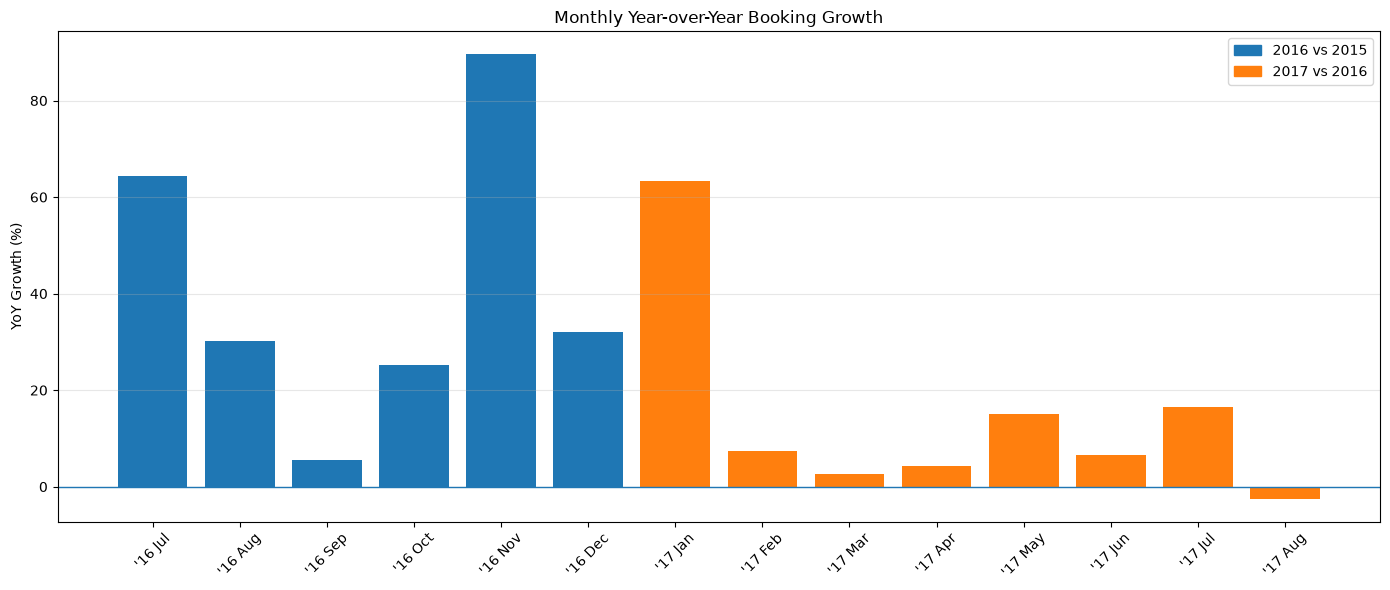

In [24]:
import numpy as np
from matplotlib.patches import Patch
x = np.arange(len(growth_summary))
colors = growth_summary['Comparison'].map({'2016 vs 2015': 'tab:blue', '2017 vs 2016': 'tab:orange'})
labels = growth_summary['Comparison'].str[:4].str[-2:].radd("'") + ' ' + growth_summary['Months'].str[:3]

plt.figure(figsize=(14, 6))
plt.bar(x, growth_summary['YoY Growth (%)'], color=colors)
plt.xticks(x, labels, rotation=45)
plt.axhline(0, linewidth=1)
plt.title('Monthly Year-over-Year Booking Growth')
plt.ylabel('YoY Growth (%)')
plt.legend(handles=[Patch(color='tab:blue', label='2016 vs 2015'),
                    Patch(color='tab:orange', label='2017 vs 2016')])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Finding:** growth was strongest from 2015 to 2016 and slowed from 2016 to 2017: apart from
January (+64%), months grew between about 3% and 16%, and August declined slightly.

*Note: 2015 comparisons should be read with caution. The data begins in July 2015, and very large
increases (such as +90% in November) may partly reflect how data was recorded in the dataset's
first months rather than real growth.*

### 4.5 City Hotel vs. Resort Hotel Seasonality (Realized Stays, 2016)
2016 is used because it is the only complete year. Only realized stays are counted.

In [25]:
(df['hotel'].value_counts(normalize=True) * 100).round(1)

hotel
City Hotel      66.4
Resort Hotel    33.6
Name: proportion, dtype: float64

In [26]:
year_data_2016 = df[(df['arrival_date_year'] == 2016) & (df['realized'])]
year_data_2016
month_data_2016 = year_data_2016.groupby(['hotel', 'arrival_date_month']).size()
month_data_2016 = month_data_2016.unstack()
month_data_2016 = month_data_2016[month_order]
month_data_2016

arrival_date_month,January,February,March,April,May,June,July,August,September,October,November,December
hotel,,,,,,,,,,,,
City Hotel,926,1436,1933,2020,2237,2201,2081,2123,2301,2265,1744,1396
Resort Hotel,765,1113,1409,1345,1323,993,985,1107,1068,1417,1056,1055


In [27]:
city_2016 = month_data_2016.loc['City Hotel']
resort_2016 = month_data_2016.loc['Resort Hotel']
print(city_2016)
print(resort_2016)

arrival_date_month
January       926
February     1436
March        1933
April        2020
May          2237
June         2201
July         2081
August       2123
September    2301
October      2265
November     1744
December     1396
Name: City Hotel, dtype: int64
arrival_date_month
January       765
February     1113
March        1409
April        1345
May          1323
June          993
July          985
August       1107
September    1068
October      1417
November     1056
December     1055
Name: Resort Hotel, dtype: int64


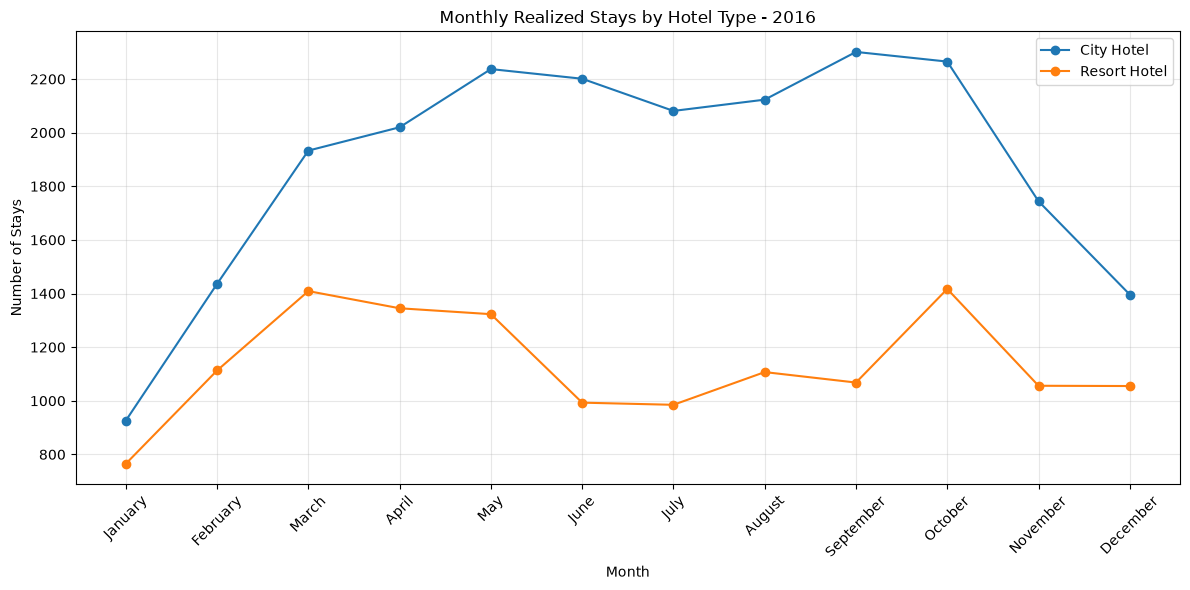

In [28]:
plt.figure(figsize=(12, 6))
plt.plot(
    city_2016.index,
    city_2016.values,
    marker='o',
    label='City Hotel'
)
plt.plot(
    resort_2016.index,
    resort_2016.values,
    marker='o',
    label='Resort Hotel'
)
plt.title('Monthly Realized Stays by Hotel Type - 2016')
plt.xlabel('Month')
plt.ylabel('Number of Stays')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [29]:
city_average_2016 = city_2016.mean()
resort_average_2016 = resort_2016.mean()
city_normalized_2016 = city_2016 / city_average_2016
resort_normalized_2016 = resort_2016 / resort_average_2016
print(city_normalized_2016)
print(resort_normalized_2016)

arrival_date_month
January      0.490315
February     0.760358
March        1.023519
April        1.069585
May          1.184486
June         1.165424
July         1.101884
August       1.124123
September    1.218374
October      1.199312
November     0.923443
December     0.739178
Name: City Hotel, dtype: float64
arrival_date_month
January      0.673218
February     0.979466
March        1.239953
April        1.183632
May          1.164271
June         0.873863
July         0.866823
August       0.974186
September    0.939865
October      1.246993
November     0.929305
December     0.928425
Name: Resort Hotel, dtype: float64


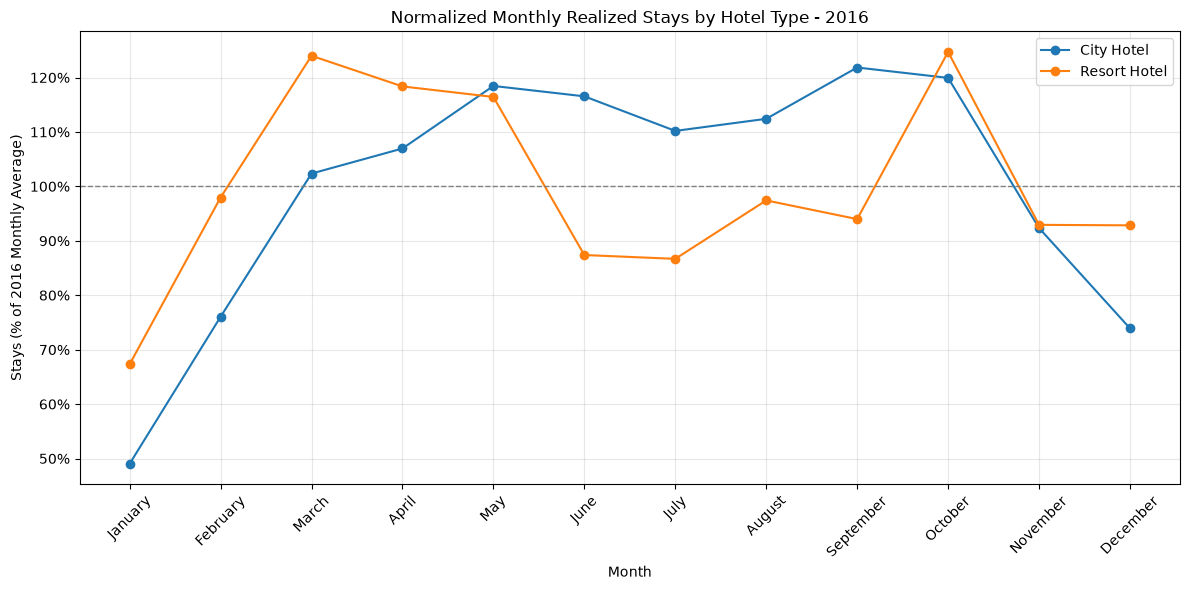

In [30]:
from matplotlib.ticker import PercentFormatter

city_normalized_2016 = city_2016 / city_average_2016
resort_normalized_2016 = resort_2016 / resort_average_2016

plt.figure(figsize=(12, 6))

plt.plot(
    city_normalized_2016.index,
    city_normalized_2016.values,
    marker='o',
    label='City Hotel'
)

plt.plot(
    resort_normalized_2016.index,
    resort_normalized_2016.values,
    marker='o',
    label='Resort Hotel'
)

plt.axhline(1, color='gray', linestyle='--', linewidth=1)

plt.title('Normalized Monthly Realized Stays by Hotel Type - 2016')
plt.xlabel('Month')
plt.ylabel('Stays (% of 2016 Monthly Average)')

plt.gca().yaxis.set_major_formatter(PercentFormatter(1))

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

The Resort Hotel’s June–July dip is unexpected for a beach resort. One possible explanation is that summer guests stay longer, so there are fewer stays but more nights per stay.

## 5. Cancellation Analysis

In [31]:
print("Overall cancellation rate:", round(df['is_canceled'].mean() * 100, 1), "%")
df.groupby('hotel')['is_canceled'].mean().round(3)

Overall cancellation rate: 37.1 %


hotel
City Hotel      0.418
Resort Hotel    0.278
Name: is_canceled, dtype: float64

### 5.1 Cancellation by Lead Time

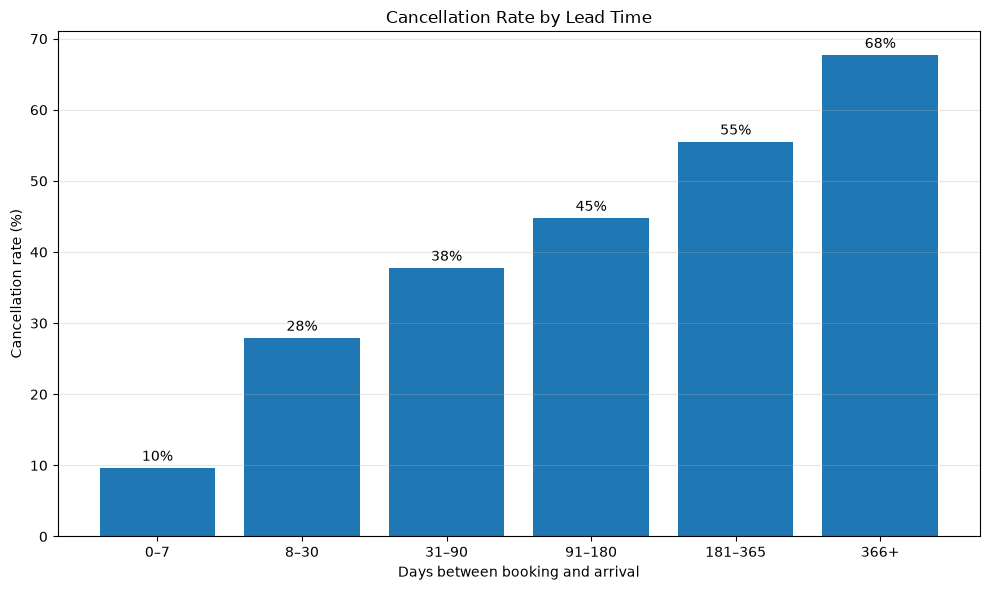

In [32]:
lead_bins = pd.cut(df['lead_time'],
                   bins=[-1, 7, 30, 90, 180, 365, 800],
                   labels=['0–7', '8–30', '31–90', '91–180', '181–365', '366+'])
lead_cancel = df.groupby(lead_bins, observed=True)['is_canceled'].mean() * 100

plt.figure(figsize=(10, 6))
bars = plt.bar(lead_cancel.index.astype(str), lead_cancel.values)
plt.bar_label(bars, fmt='%.0f%%', padding=3)
plt.title('Cancellation Rate by Lead Time')
plt.xlabel('Days between booking and arrival')
plt.ylabel('Cancellation rate (%)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Finding:** cancellation risk rises steadily with lead time, from **10%** for bookings made within
a week of arrival to **68%** for bookings made more than a year ahead.

### 5.2 Cancellation by Deposit Type and Market Segment

In [33]:
df.groupby('deposit_type')['is_canceled'].agg(['mean', 'size']).round(3)

,mean,size
deposit_type,,
No Deposit,0.284,104460
Non Refund,0.994,14586
Refundable,0.222,162


In [34]:
df.groupby('market_segment')['is_canceled'].agg(['mean', 'size']).round(3).sort_values('mean')

,mean,size
market_segment,,
Complementary,0.122,728
Direct,0.154,12582
Corporate,0.188,5282
Aviation,0.221,235
Offline TA/TO,0.343,24181
Online TA,0.368,56408
Groups,0.611,19790
Undefined,1.000,2


**Finding:** group bookings cancel most often (61%), while direct bookings cancel least (15%).
"Undefined" shows 100% but is based on only 2 bookings, so it is ignored. Non-refundable deposits
show a 99.4% cancellation rate, the opposite of what a deposit should do, which is investigated next.

### 5.3 The Non-Refundable Deposit Puzzle

In [35]:
nr = df[df['deposit_type'] == 'Non Refund']
print(nr['hotel'].value_counts(normalize=True).round(2))
print(nr['market_segment'].value_counts(normalize=True).round(2).head(3))
print(nr['country'].value_counts(normalize=True).round(2).head(3))
print("Median lead time:", nr['lead_time'].median(), "vs. all:", df['lead_time'].median())
print("Share that are duplicate rows:", round(nr.duplicated().mean(), 2))

hotel
City Hotel      0.88
Resort Hotel    0.12
Name: proportion, dtype: float64
market_segment
Groups           0.63
Offline TA/TO    0.34
Corporate        0.02
Name: proportion, dtype: float64
country
PRT    0.97
GBR    0.01
ESP    0.01
Name: proportion, dtype: float64
Median lead time: 183.0 vs. all: 69.0
Share that are duplicate rows: 0.93


Non-refundable bookings cancel 99% of the time, the opposite of what deposits should do. These bookings are 88% City Hotel, 63% group bookings, and 97% from Portugal, are made about 6 months ahead (median 183 days vs. 69 overall), and 93% are duplicate rows. This pattern suggests large group room blocks held by tour operators and later released, rather than individual guests losing their deposits. Because of this, the Non Refund category shouldn’t be read as evidence that deposits increase cancellations.

### 5.4 Other Signals

In [36]:
for col in ['is_repeated_guest', 'total_of_special_requests']:
    print(df.groupby(col)['is_canceled'].mean().round(3), '\n')
print(df.groupby(df['previous_cancellations'] > 0)['is_canceled'].mean().round(3))

is_repeated_guest
0    0.378
1    0.147
Name: is_canceled, dtype: float64 

total_of_special_requests
0    0.478
1    0.220
2    0.221
3    0.178
4    0.106
5    0.050
Name: is_canceled, dtype: float64 

previous_cancellations
False    0.339
True     0.917
Name: is_canceled, dtype: float64


**Finding:** repeat guests cancel far less (15% vs. 38%), guests with no special requests cancel
48% of the time compared with about 22% for those with at least one, and guests who canceled before
cancel 92% of the time. Guests who engage with their booking are much less likely to cancel.

## 6. Predicting Cancellation

Section 5 looked at each factor on its own. A **logistic regression** shows which factors still
matter when considered together, and how well they predict cancellations on new data.

- **Why logistic regression:** the outcome is yes/no (canceled or not); the model predicts a probability,
  and its coefficients convert to **odds ratios** that are easy to interpret.
- **Train/test split by time:** the model is trained on 2015–2016 arrivals and tested on 2017 arrivals,
  the way a hotel would use it. This also keeps duplicate group rows from appearing in both sets.

In [37]:
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

m = df.copy()
m['lead_100'] = m['lead_time'] / 100                       # lead time in 100-day units
m['prev_cancel'] = (m['previous_cancellations'] > 0).astype(int)
m['any_request'] = (m['total_of_special_requests'] > 0).astype(int)
m['any_change'] = (m['booking_changes'] > 0).astype(int)
m['segment'] = m['market_segment'].replace(
    {'Undefined': 'Online TA', 'Aviation': 'Corporate', 'Complementary': 'Direct'})

In [38]:
train = m[m['arrival_date'] < '2017-01-01']    # 2015–2016 arrivals
test  = m[m['arrival_date'] >= '2017-01-01']   # 2017 arrivals

In [39]:
formula = ('is_canceled ~ lead_100 + C(hotel) + C(segment, Treatment("Online TA"))'
           ' + prev_cancel + is_repeated_guest + any_request + any_change + total_nights')
model = smf.logit(formula, data=train).fit()

odds = pd.DataFrame({'odds_ratio': np.exp(model.params),
                     'p_value': model.pvalues}).round(3)
odds

Optimization terminated successfully.
         Current function value: 0.480493
         Iterations 8


,odds_ratio,p_value
Intercept,0.947,0.012
C(hotel)[T.Resort Hotel],0.609,0.000
"C(segment, Treatment(""Online TA""))[T.Corporate]",0.210,0.000
"C(segment, Treatment(""Online TA""))[T.Direct]",0.288,0.000
"C(segment, Treatment(""Online TA""))[T.Groups]",0.633,0.000
"C(segment, Treatment(""Online TA""))[T.Offline TA/TO]",0.305,0.000
lead_100,1.701,0.000
prev_cancel,90.149,0.000
is_repeated_guest,0.086,0.000
any_request,0.209,0.000


**How to read the odds ratios** (all p-values < 0.001)
- **Lead time (1.70):** each extra 100 days of lead time raises the odds of cancellation by about 70%.
- **Resort Hotel (0.61):** Resort bookings have about 39% lower odds of cancellation than City Hotel bookings, other factors held equal.
- **Special requests (0.21) and booking changes (0.28):** guests who engage with their booking are much less likely to cancel.
- **Repeat guests (0.09):** about 91% lower odds than first-time guests.
- **Direct (0.29) and Corporate (0.21):** much lower risk than Online travel agencies (the reference group).
- **Groups (0.63):** in Section 5.2 groups had the highest raw cancellation rate (61%), but compared with similar bookings they have *lower* odds than Online TA. Group bookings are made very far ahead, and **lead time explains most of their high cancellation rate**.
- **Previous cancellation (≈90):** very large, likely inflated by repeated group records rather than individual guest behavior, so it should be interpreted with caution.

In [40]:
p = model.predict(test)
print("AUC:", round(roc_auc_score(test['is_canceled'], p), 3))
print("Accuracy:", round(((p > 0.5) == test['is_canceled']).mean(), 3))
print("Baseline (always predict 'not canceled'):", round(1 - test['is_canceled'].mean(), 3))

AUC: 0.75
Accuracy: 0.7
Baseline (always predict 'not canceled'): 0.613


**Model performance:** AUC of **0.75** on held-out 2017 data, meaning the model ranks a randomly chosen canceled booking above a non-canceled one 75% of the time (0.5 = guessing, 1.0 = perfect). Accuracy is 70%, compared with 61% for always predicting "not canceled." This is solid for a simple, explainable model that uses no leaked information.

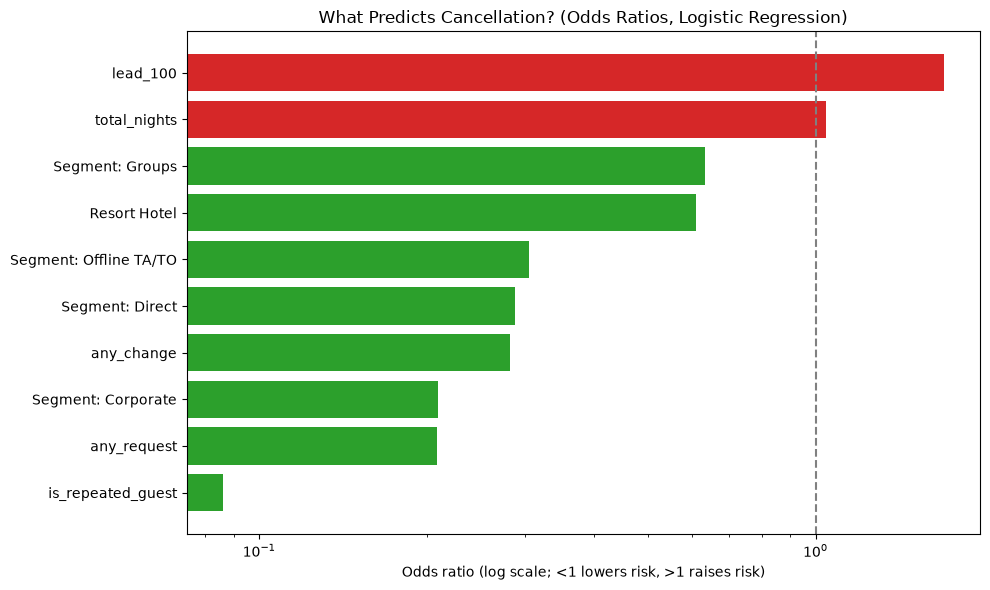

In [41]:
plot_or = odds.drop('Intercept')['odds_ratio'].drop('prev_cancel').sort_values()
plot_or.index = (plot_or.index.str.replace(r'C\(segment, Treatment\("Online TA"\)\)\[T\.', 'Segment: ', regex=True)
                              .str.replace(r'C\(hotel\)\[T\.', '', regex=True).str.rstrip(']'))
colors = ['tab:green' if v < 1 else 'tab:red' for v in plot_or]

plt.figure(figsize=(10, 6))
plt.barh(plot_or.index, plot_or.values, color=colors)
plt.axvline(1, color='gray', linestyle='--')
plt.xscale('log')
plt.title('What Predicts Cancellation? (Odds Ratios, Logistic Regression)')
plt.xlabel('Odds ratio (log scale; <1 lowers risk, >1 raises risk)')
plt.tight_layout()
plt.show()

## 7. Key Findings and Recommendations

### Key Findings
1. **Bookings overstate demand.** 37% of bookings are canceled. From January–August 2016 to 2017, bookings grew about 10.5% but realized stays grew only about 3.7%.
2. **Strong, hotel-specific seasonality.** The City Hotel drops to about half its average volume in January and peaks in September, while the Resort Hotel peaks in March and October.
3. **Lead time is the strongest cancellation signal.** Cancellation rates rise from 10% for bookings made within a week to 68% for bookings made more than a year ahead, and lead time remains significant in the regression (odds ratio 1.70 per 100 days).
4. **Engaged and loyal guests rarely cancel.** Special requests, booking changes, and repeat stays all sharply lower cancellation odds, while online travel agency bookings carry the highest risk.
5. **The "Non Refund" category is a data artifact.** Its 99% cancellation rate most likely reflects group room blocks held by tour operators, not individual guests.
6. **Cancellations are reasonably predictable.** A simple logistic regression reaches an AUC of 0.75 on unseen 2017 data.

### Recommendations
- **Plan with realized stays, not bookings,** when forecasting occupancy, staffing, and budgets.
- **Manage long-lead and online travel agency bookings more carefully,** for example with stricter deposit terms or targeted overbooking based on predicted cancellation risk.
- **Encourage early engagement** (pre-arrival requests, loyalty perks for repeat guests), which is associated with much lower cancellation rates.

### Limitations
- 2015 and 2017 are partial years, and early 2015 data may reflect recording effects.
- The dataset has no booking ID, so group bookings appear as duplicate rows.
- The model shows associations, not causes.